Saving Tweets.csv to Tweets.csv
Dataset shape: (14640, 15)
             tweet_id airline_sentiment  airline_sentiment_confidence  \
0  570306133677760513           neutral                        1.0000   
1  570301130888122368          positive                        0.3486   
2  570301083672813571           neutral                        0.6837   
3  570301031407624196          negative                        1.0000   
4  570300817074462722          negative                        1.0000   

  negativereason  negativereason_confidence         airline  \
0            NaN                        NaN  Virgin America   
1            NaN                     0.0000  Virgin America   
2            NaN                        NaN  Virgin America   
3     Bad Flight                     0.7033  Virgin America   
4     Can't Tell                     1.0000  Virgin America   

  airline_sentiment_gold        name negativereason_gold  retweet_count  \
0                    NaN     cairdin            

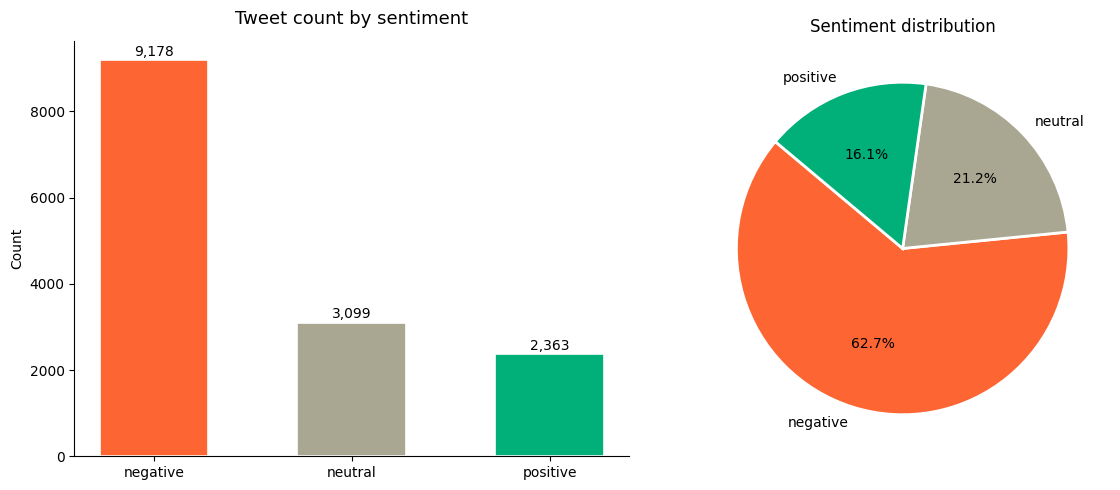


Negative reasons:
negativereason
Customer Service Issue         2910
Late Flight                    1665
Can't Tell                     1190
Cancelled Flight                847
Lost Luggage                    724
Bad Flight                      580
Flight Booking Problems         529
Flight Attendant Complaints     481
longlines                       178
Damaged Luggage                  74
Name: count, dtype: int64


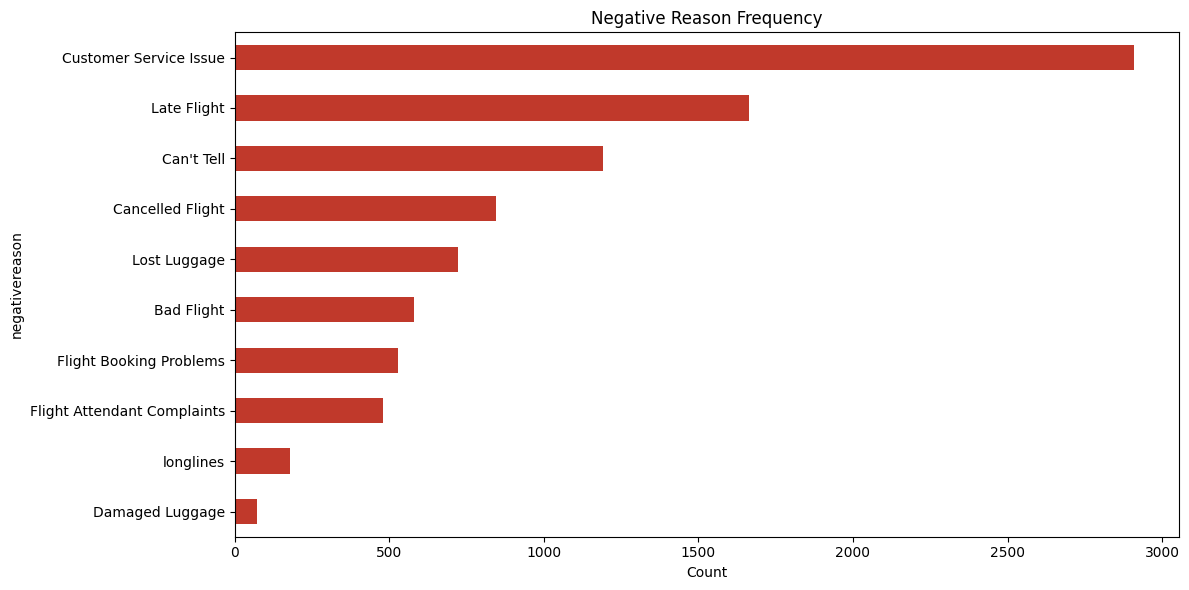


Sentiment by airline:
airline_sentiment  negative  neutral  positive
airline                                       
American               1960      463       336
Delta                   955      723       544
Southwest              1186      664       570
US Airways             2263      381       269
United                 2633      697       492
Virgin America          181      171       152


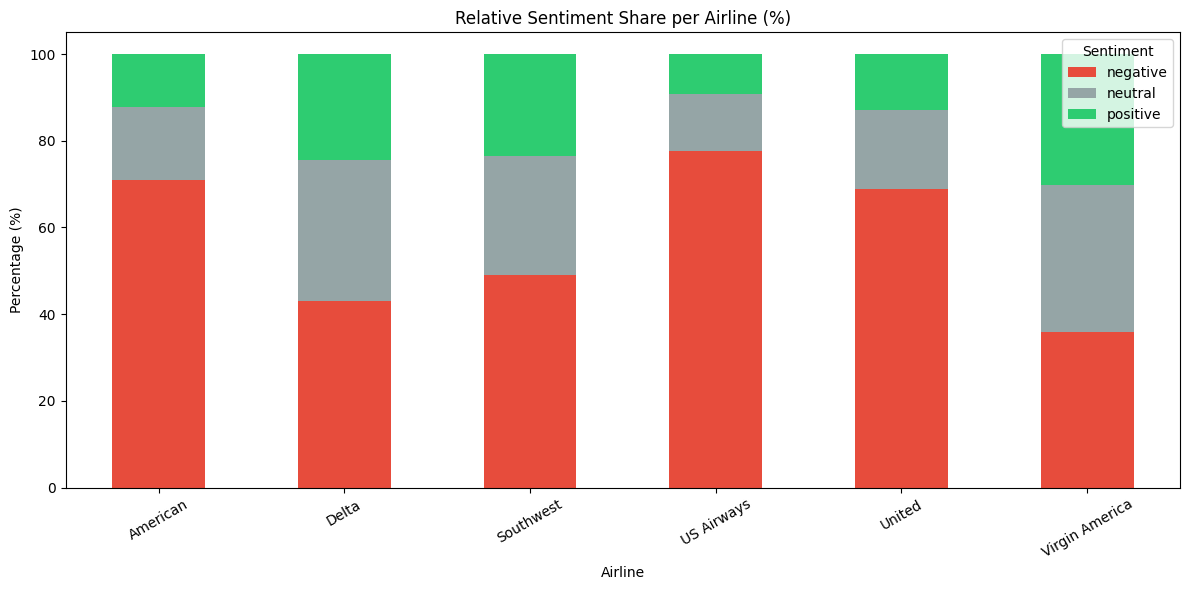

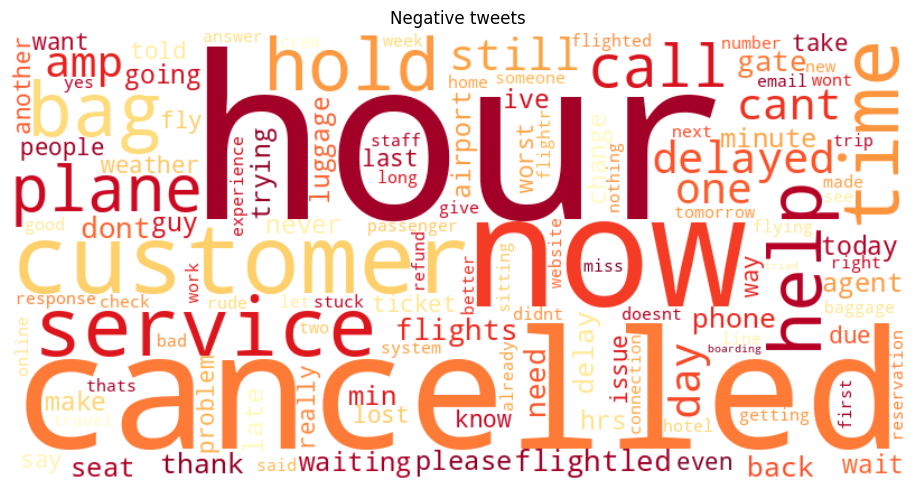

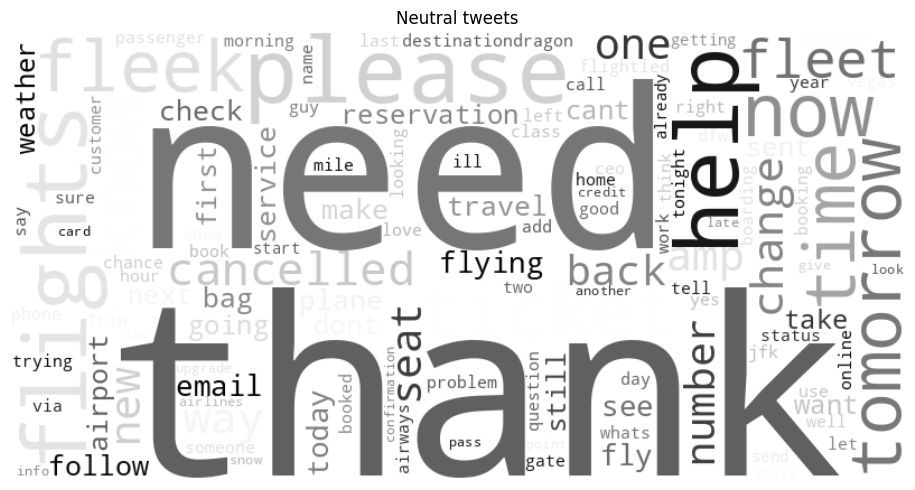

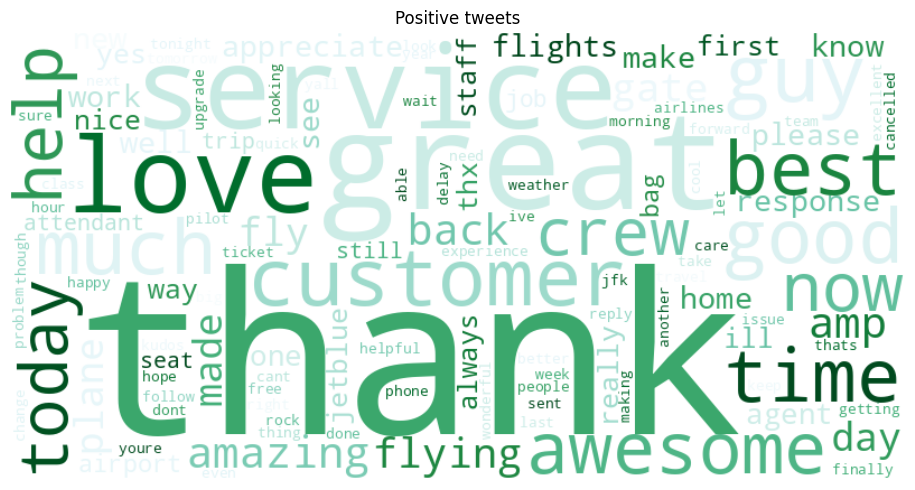

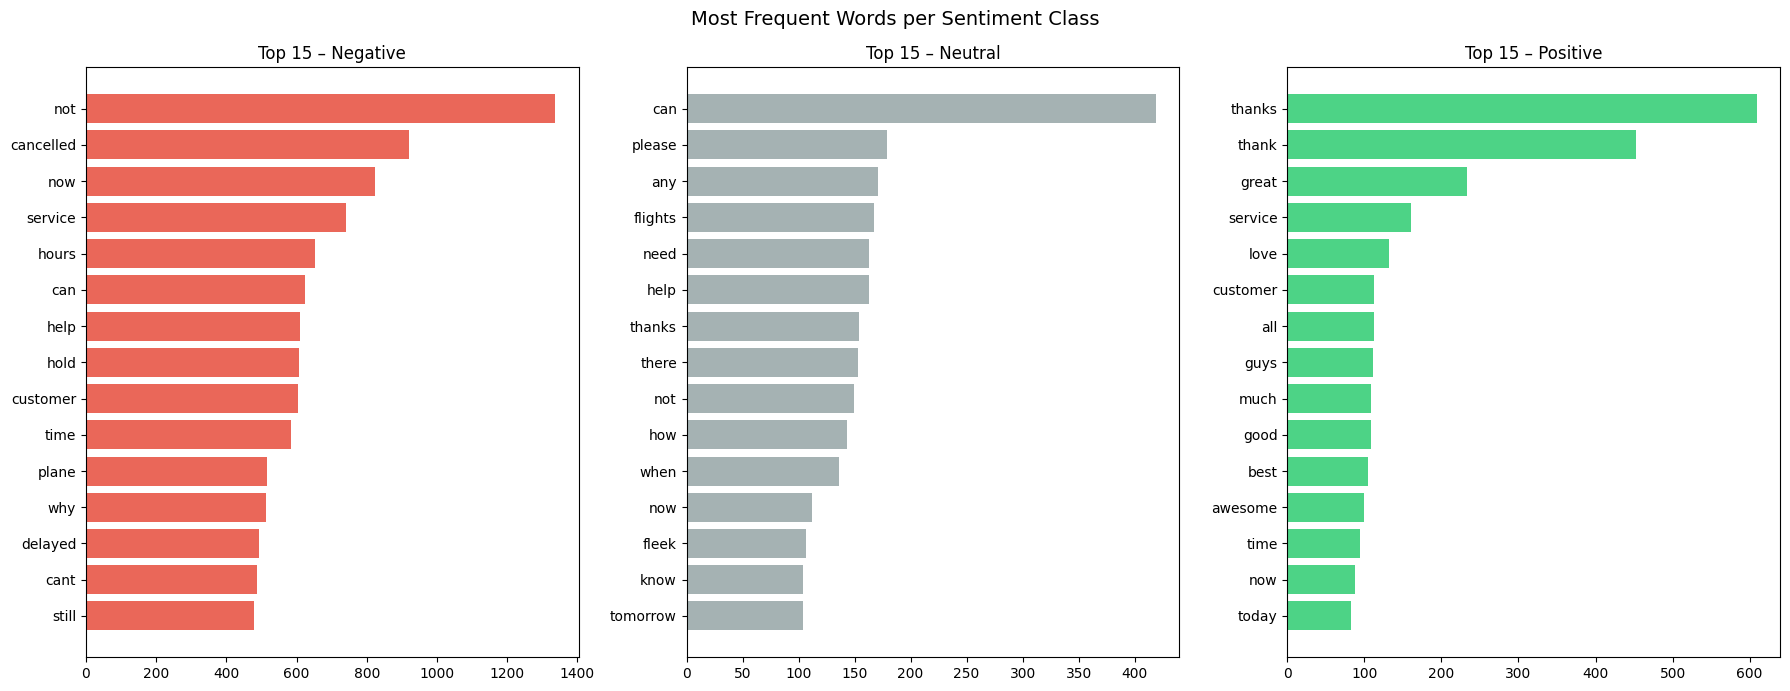


NAIVE BAYES RESULTS
              precision    recall  f1-score   support

    negative       0.77      0.96      0.85      1835
     neutral       0.71      0.38      0.50       620
    positive       0.79      0.53      0.64       473

    accuracy                           0.77      2928
   macro avg       0.76      0.62      0.66      2928
weighted avg       0.76      0.77      0.74      2928



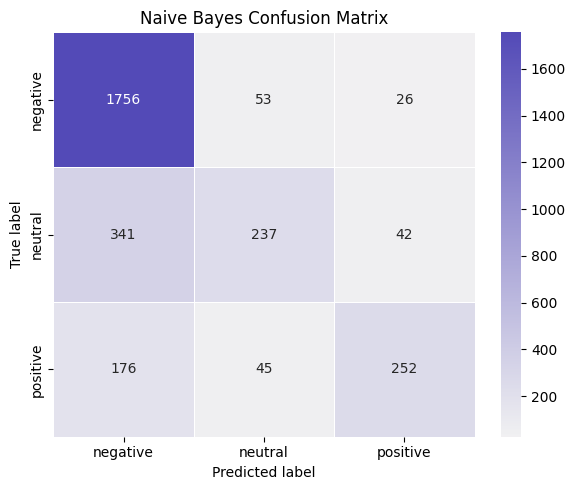


TF-IDF RESULTS
Training matrix: (11712, 4837)
Testing matrix: (2928, 4837)
Vocabulary size: 4837

LOGISTIC REGRESSION - NO CLASS WEIGHTING
              precision    recall  f1-score   support

    negative       0.81      0.94      0.87      1835
     neutral       0.67      0.50      0.57       620
    positive       0.82      0.58      0.68       473

    accuracy                           0.79      2928
   macro avg       0.77      0.68      0.71      2928
weighted avg       0.78      0.79      0.78      2928



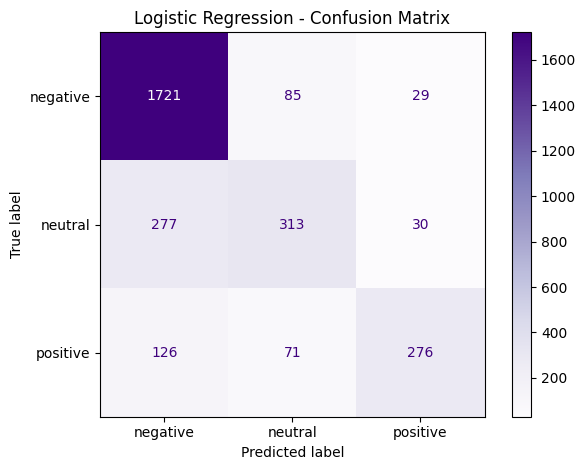


LOGISTIC REGRESSION - BALANCED CLASS WEIGHTS
              precision    recall  f1-score   support

    negative       0.89      0.79      0.83      1835
     neutral       0.53      0.69      0.60       620
    positive       0.69      0.71      0.70       473

    accuracy                           0.76      2928
   macro avg       0.70      0.73      0.71      2928
weighted avg       0.78      0.76      0.76      2928



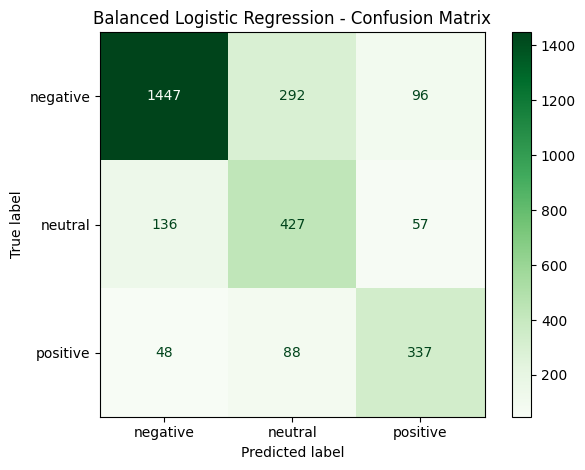


LOGISTIC REGRESSION MODEL COMPARISON
                          Model  Accuracy  Balanced Accuracy  Macro F1
0           Logistic Regression    0.7889             0.6754    0.7091
1  Logistic Regression Balanced    0.7551             0.7299    0.7111

Full TF-IDF matrix: (14640, 5468)

PCA explained variance: 15.79 %
Reduced dimensions: (14640, 50)


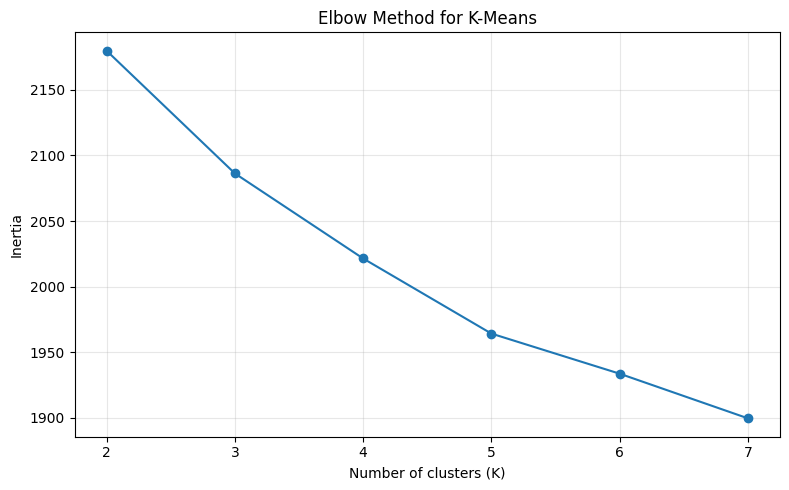


CLUSTER DISTRIBUTION
0      311
1    13334
2      995
Name: count, dtype: int64

K-MEANS EVALUATION
Purity: 0.6647
Silhouette Score: 0.1824

CLUSTER VS ACTUAL SENTIMENT
Actual Sentiment  negative  neutral  positive
Cluster                                      
0                        6       40       265
1                     8893     2916      1525
2                      279      143       573


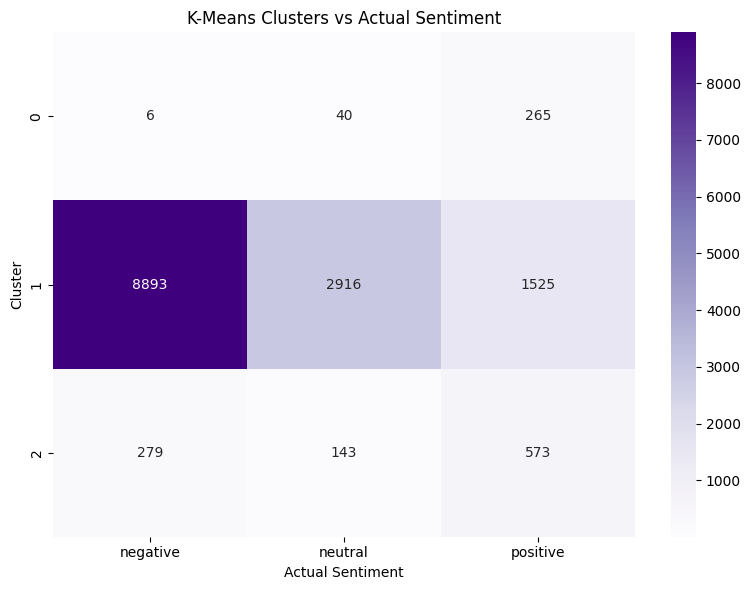


FINAL SUPERVISED MODEL COMPARISON
                            Model  Accuracy  Balanced Accuracy  Macro F1
0  Custom Multinomial Naive Bayes    0.7667             0.6240    0.6623
1             Logistic Regression    0.7889             0.6754    0.7091
2    Logistic Regression Balanced    0.7551             0.7299    0.7111

Project execution completed successfully!


In [2]:

# ============================================================
# US AIRLINE TWITTER SENTIMENT ANALYSIS
# Data Mining Project - Tunis Business School
# ============================================================


# ============================================================
# 1. INSTALL AND IMPORT LIBRARIES
# ============================================================

!pip install -q wordcloud

from google.colab import files

import pandas as pd
import numpy as np
import re
import math

from collections import defaultdict, Counter

import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    silhouette_score
)


# ============================================================
# 2. COLOR PALETTE
# ============================================================

COLORS = {
    'negative': "#FD6532",
    'neutral': "#A9A792",
    'positive': "#01AF78"
}

PALETTE = [
    COLORS['negative'],
    COLORS['neutral'],
    COLORS['positive']
]

ACCENT_PURPLE = '#534AB7'
ACCENT_BLUE = '#185FA5'
ACCENT_AMBER = '#BA7517'

FILLS = {
    'negative': '#FAECE7',
    'neutral': '#F1EFE8',
    'positive': '#E1F5EE'
}


# ============================================================
# 3. UPLOAD AND LOAD DATASET
# ============================================================

uploaded = files.upload()

df = pd.read_csv('Tweets.csv')

print("Dataset shape:", df.shape)
print(df.head())
print(df.isnull().sum())


# ============================================================
# 4. DATA CLEANING
# ============================================================

cols_to_drop = [
    'tweet_id',
    'tweet_location',
    'user_timezone',
    'negativereason_confidence',
    'airline_sentiment_confidence'
]

df.drop(columns=cols_to_drop, inplace=True)

print("\nDataset after removing unnecessary columns:")
print(df.shape)


# ============================================================
# 5. TEXT PREPROCESSING
# ============================================================

STOPWORDS = {
    'i','me','my','myself','we','our','ours','ourselves','you',
    'your','yours','yourself','he','him','his','himself','she',
    'her','hers','herself','it','its','itself','they','them',
    'their','theirs','themselves','what','which','who','whom',
    'this','that','these','those','am','is','are','was','were',
    'be','been','being','have','has','had','having','do','does',
    'did','doing','a','an','the','and','but','if','or','because',
    'as','until','while','of','at','by','for','with','about',
    'against','between','into','through','to','from','up','down',
    'in','out','on','off','over','then','once','just','so',
    'flight','airline','united','american','southwest','delta',
    'usairways','virginamerica','get','got','will','would','could'
}


def preprocess(text):

    text = str(text)

    # Remove Twitter mentions
    text = re.sub(r'@\w+', '', text)

    # Remove URLs
    text = re.sub(r'http\S+', '', text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Convert to lowercase
    text = text.lower()

    # Tokenization
    tokens = text.split()

    # Remove stopwords and short tokens
    tokens = [
        t for t in tokens
        if t not in STOPWORDS and len(t) > 2
    ]

    return tokens


df['tokens'] = df['text'].apply(preprocess)


# ============================================================
# 6. ENCODE TARGET
# ============================================================

label_map = {
    'negative': 0,
    'neutral': 1,
    'positive': 2
}

df['label'] = df['airline_sentiment'].map(label_map)

label_names = [
    'negative',
    'neutral',
    'positive'
]

print("\nSentiment distribution:")
print(df['airline_sentiment'].value_counts())


# ============================================================
# 7. TRAIN-TEST SPLIT
# ============================================================

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

print("\nTraining size:", len(train_df))
print("Testing size:", len(test_df))


# ============================================================
# 8. EXPLORATORY DATA ANALYSIS
# ============================================================

sentiment_counts = df['airline_sentiment'].value_counts()

ordered_labels = [
    'negative',
    'neutral',
    'positive'
]

ordered_counts = [
    sentiment_counts.get(label, 0)
    for label in ordered_labels
]

ordered_colors = [
    COLORS[label]
    for label in ordered_labels
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

fig.patch.set_facecolor('white')

# Bar chart

bars = axes[0].bar(
    ordered_labels,
    ordered_counts,
    color=ordered_colors,
    width=0.55,
    edgecolor='white',
    linewidth=1.2
)

axes[0].set_title(
    'Tweet count by sentiment',
    fontsize=13,
    pad=12
)

axes[0].set_ylabel('Count')

axes[0].spines[['top', 'right']].set_visible(False)

for bar, count in zip(bars, ordered_counts):

    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 40,
        f'{count:,}',
        ha='center',
        va='bottom'
    )


# Pie chart

axes[1].pie(
    ordered_counts,
    labels=ordered_labels,
    colors=ordered_colors,
    autopct='%1.1f%%',
    startangle=140,
    wedgeprops=dict(
        linewidth=2,
        edgecolor='white'
    )
)

axes[1].set_title('Sentiment distribution')

plt.tight_layout()
plt.show()


# ============================================================
# 9. NEGATIVE REASON ANALYSIS
# ============================================================

neg_df = df[
    df['airline_sentiment'] == 'negative'
]

reason_counts = (
    neg_df['negativereason']
    .value_counts()
    .dropna()
)

print("\nNegative reasons:")
print(reason_counts)

plt.figure(figsize=(12, 6))

reason_counts.plot(
    kind='barh',
    color='#C0392B'
)

plt.title('Negative Reason Frequency')
plt.xlabel('Count')

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    'fig4_neg_reasons.png',
    dpi=150
)

plt.show()


# ============================================================
# 10. SENTIMENT BY AIRLINE
# ============================================================

airline_sent = (
    df.groupby([
        'airline',
        'airline_sentiment'
    ])
    .size()
    .unstack(fill_value=0)
)

print("\nSentiment by airline:")
print(airline_sent)

airline_pct = (
    airline_sent.div(
        airline_sent.sum(axis=1),
        axis=0
    ) * 100
)

airline_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    color=[
        '#E74C3C',
        '#95A5A6',
        '#2ECC71'
    ]
)

plt.title('Relative Sentiment Share per Airline (%)')
plt.xlabel('Airline')
plt.ylabel('Percentage (%)')

plt.xticks(rotation=30)

plt.legend(title='Sentiment')

plt.tight_layout()

plt.savefig(
    'fig3_airline_pct.png',
    dpi=150
)

plt.show()


# ============================================================
# 11. WORD CLOUDS
# ============================================================

WC_COLORMAPS = {
    0: 'YlOrRd',
    1: 'Greys',
    2: 'BuGn'
}

WC_TITLES = {
    0: 'Negative tweets',
    1: 'Neutral tweets',
    2: 'Positive tweets'
}


def generate_wordcloud(texts, label_id):

    all_tokens = ' '.join([
        ' '.join(tokens)
        for tokens in texts
    ])

    wc = WordCloud(
        width=800,
        height=400,
        background_color='white',
        colormap=WC_COLORMAPS[label_id],
        max_words=120,
        collocations=False
    ).generate(all_tokens)

    plt.figure(figsize=(10, 5))

    plt.imshow(
        wc,
        interpolation='bilinear'
    )

    plt.axis('off')

    plt.title(WC_TITLES[label_id])

    plt.tight_layout()

    plt.show()


for label_id in [0, 1, 2]:

    generate_wordcloud(
        df[df['label'] == label_id]['tokens'],
        label_id
    )


# ============================================================
# 12. TOP 15 WORDS PER SENTIMENT
# ============================================================

def top_words(label, n=15):

    tokens = df[
        df['airline_sentiment'] == label
    ]['tokens']

    flat = [
        token
        for sublist in tokens
        for token in sublist
    ]

    return Counter(flat).most_common(n)


top_neg = top_words('negative')
top_neu = top_words('neutral')
top_pos = top_words('positive')

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 7)
)

for ax, data, title, color in zip(
    axes,
    [top_neg, top_neu, top_pos],
    ['Negative', 'Neutral', 'Positive'],
    ['#E74C3C', '#95A5A6', '#2ECC71']
):

    words, counts = zip(*data)

    ax.barh(
        range(len(words)),
        counts,
        color=color,
        alpha=0.85
    )

    ax.set_yticks(range(len(words)))
    ax.set_yticklabels(words)

    ax.invert_yaxis()

    ax.set_title(f'Top 15 – {title}')

plt.suptitle(
    'Most Frequent Words per Sentiment Class',
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    'fig12_top_words.png',
    dpi=150
)

plt.show()


# ============================================================
# 13. BUILD VOCABULARY
# ============================================================

def build_vocab(tokens_list):

    vocab = set()

    for tokens in tokens_list:
        vocab.update(tokens)

    return sorted(vocab)


vocab = build_vocab(
    train_df['tokens']
)


# ============================================================
# 14. MULTINOMIAL NAIVE BAYES
# ============================================================

class MultinomialNaiveBayes:

    def __init__(self, alpha=1.0):

        self.alpha = alpha


    def fit(self, X_tokens, y, vocab):

        self.classes = sorted(y.unique())

        self.vocab = vocab

        V = len(vocab)

        self.log_prior = {}

        self.log_likelihood = {}

        for c in self.classes:

            class_tokens = [
                token
                for tokens, label in zip(X_tokens, y)
                if label == c
                for token in tokens
            ]

            N_c = len(class_tokens)

            self.log_prior[c] = math.log(
                sum(y == c) / len(y)
            )

            counts = defaultdict(int)

            for token in class_tokens:
                counts[token] += 1

            denom = math.log(
                N_c + self.alpha * V
            )

            self.log_likelihood[c] = {

                word: (
                    math.log(
                        counts.get(word, 0) + self.alpha
                    ) - denom
                )

                for word in vocab
            }


    def predict(self, X_tokens):

        predictions = []

        for tokens in X_tokens:

            scores = {}

            for c in self.classes:

                score = self.log_prior[c]

                score += sum(
                    self.log_likelihood[c].get(t, 0)
                    for t in tokens
                )

                scores[c] = score

            predictions.append(
                max(scores, key=scores.get)
            )

        return predictions


# ============================================================
# 15. TRAIN AND EVALUATE NAIVE BAYES
# ============================================================

nb = MultinomialNaiveBayes()

nb.fit(
    train_df['tokens'],
    train_df['label'],
    vocab
)

y_pred_nb = nb.predict(
    test_df['tokens']
)

y_true = test_df['label']

print("\nNAIVE BAYES RESULTS")

print(
    classification_report(
        y_true,
        y_pred_nb,
        labels=[0, 1, 2],
        target_names=label_names,
        zero_division=0
    )
)

cm_nb = confusion_matrix(
    y_true,
    y_pred_nb,
    labels=[0, 1, 2]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap=sns.light_palette(
        ACCENT_PURPLE,
        as_cmap=True
    ),
    xticklabels=label_names,
    yticklabels=label_names,
    linewidths=0.5,
    linecolor='white'
)

plt.title('Naive Bayes Confusion Matrix')

plt.xlabel('Predicted label')
plt.ylabel('True label')

plt.tight_layout()
plt.show()


# ============================================================
# 16. TF-IDF FEATURE EXTRACTION
# ============================================================

X_train_tokens = (
    train_df['tokens']
    .apply(lambda x: ' '.join(x))
)

X_test_tokens = (
    test_df['tokens']
    .apply(lambda x: ' '.join(x))
)

tfidf = TfidfVectorizer(
    sublinear_tf=True,
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf.fit_transform(
    X_train_tokens
)

X_test_tfidf = tfidf.transform(
    X_test_tokens
)

y_train = train_df['label']
y_test = test_df['label']

print("\nTF-IDF RESULTS")

print(
    "Training matrix:",
    X_train_tfidf.shape
)

print(
    "Testing matrix:",
    X_test_tfidf.shape
)

print(
    "Vocabulary size:",
    len(tfidf.vocabulary_)
)


# ============================================================
# 17. LOGISTIC REGRESSION WITHOUT CLASS WEIGHTING
# ============================================================

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(
    X_train_tfidf,
    y_train
)

y_pred_lr = lr_model.predict(
    X_test_tfidf
)

print("\nLOGISTIC REGRESSION - NO CLASS WEIGHTING")

print(
    classification_report(
        y_test,
        y_pred_lr,
        labels=[0, 1, 2],
        target_names=label_names,
        zero_division=0
    )
)


# Confusion matrix

cm_lr = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=label_names
)

disp.plot(
    cmap='Purples',
    values_format='d'
)

plt.title(
    'Logistic Regression - Confusion Matrix'
)

plt.tight_layout()
plt.show()


# ============================================================
# 18. LOGISTIC REGRESSION WITH BALANCED CLASS WEIGHTS
# ============================================================

lr_balanced = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

lr_balanced.fit(
    X_train_tfidf,
    y_train
)

y_pred_balanced = lr_balanced.predict(
    X_test_tfidf
)

print("\nLOGISTIC REGRESSION - BALANCED CLASS WEIGHTS")

print(
    classification_report(
        y_test,
        y_pred_balanced,
        labels=[0, 1, 2],
        target_names=label_names,
        zero_division=0
    )
)


# Confusion matrix

cm_balanced = confusion_matrix(
    y_test,
    y_pred_balanced,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=label_names
)

disp.plot(
    cmap='Greens',
    values_format='d'
)

plt.title(
    'Balanced Logistic Regression - Confusion Matrix'
)

plt.tight_layout()
plt.show()


# ============================================================
# 19. COMPARE LOGISTIC REGRESSION MODELS
# ============================================================

models = {
    'Logistic Regression': y_pred_lr,
    'Logistic Regression Balanced': y_pred_balanced
}

comparison = []

for model_name, predictions in models.items():

    comparison.append({

        'Model': model_name,

        'Accuracy': accuracy_score(
            y_test,
            predictions
        ),

        'Balanced Accuracy': balanced_accuracy_score(
            y_test,
            predictions
        ),

        'Macro F1': f1_score(
            y_test,
            predictions,
            average='macro'
        )

    })


comparison_df = pd.DataFrame(comparison)

print("\nLOGISTIC REGRESSION MODEL COMPARISON")

print(
    comparison_df.round(4)
)


# ============================================================
# 20. PCA DIMENSIONALITY REDUCTION
# ============================================================

# For the clustering experiment, fit TF-IDF on the
# complete dataset, as clustering is unsupervised.

all_text = (
    df['tokens']
    .apply(lambda x: ' '.join(x))
)

tfidf_all = TfidfVectorizer(
    sublinear_tf=True,
    min_df=2,
    max_df=0.95
)

X_all_tfidf = tfidf_all.fit_transform(
    all_text
)

print("\nFull TF-IDF matrix:", X_all_tfidf.shape)

# PCA requires a dense matrix.
# Keep the first 50 principal components.

X_all_dense = X_all_tfidf.toarray()

pca = PCA(
    n_components=50,
    random_state=42
)

X_pca = pca.fit_transform(
    X_all_dense
)

explained_variance = (
    pca.explained_variance_ratio_.sum() * 100
)

print(
    "\nPCA explained variance:",
    round(explained_variance, 2),
    "%"
)

print(
    "Reduced dimensions:",
    X_pca.shape
)


# ============================================================
# 21. ELBOW METHOD
# ============================================================

inertias = []

K_range = range(2, 8)

for k in K_range:

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    km.fit(X_pca)

    inertias.append(
        km.inertia_
    )


plt.figure(figsize=(8, 5))

plt.plot(
    list(K_range),
    inertias,
    marker='o'
)

plt.title('Elbow Method for K-Means')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')

plt.xticks(list(K_range))

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 22. K-MEANS CLUSTERING
# ============================================================

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(
    X_pca
)

print("\nCLUSTER DISTRIBUTION")

print(
    pd.Series(clusters)
    .value_counts()
    .sort_index()
)


# ============================================================
# 23. CLUSTERING EVALUATION
# ============================================================

def calculate_purity(y_true, clusters):

    contingency = pd.crosstab(
        pd.Series(y_true, name='True'),
        pd.Series(clusters, name='Cluster')
    )

    return (
        contingency.max(axis=0).sum()
        / len(y_true)
    )


purity = calculate_purity(
    df['label'].values,
    clusters
)

silhouette = silhouette_score(
    X_pca,
    clusters
)

print("\nK-MEANS EVALUATION")

print(
    "Purity:",
    round(purity, 4)
)

print(
    "Silhouette Score:",
    round(silhouette, 4)
)


# ============================================================
# 24. CLUSTER VS TRUE SENTIMENT
# ============================================================

cluster_comparison = pd.crosstab(
    pd.Series(clusters, name='Cluster'),
    pd.Series(
        df['airline_sentiment'].values,
        name='Actual Sentiment'
    )
)

print("\nCLUSTER VS ACTUAL SENTIMENT")

print(cluster_comparison)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cluster_comparison,
    annot=True,
    fmt='d',
    cmap='Purples'
)

plt.title(
    'K-Means Clusters vs Actual Sentiment'
)

plt.tight_layout()
plt.show()


# ============================================================
# 25. FINAL MODEL COMPARISON
# ============================================================

final_models = {

    'Custom Multinomial Naive Bayes': y_pred_nb,

    'Logistic Regression': y_pred_lr,

    'Logistic Regression Balanced': y_pred_balanced

}

final_comparison = []

for model_name, predictions in final_models.items():

    final_comparison.append({

        'Model': model_name,

        'Accuracy': accuracy_score(
            y_test,
            predictions
        ),

        'Balanced Accuracy': balanced_accuracy_score(
            y_test,
            predictions
        ),

        'Macro F1': f1_score(
            y_test,
            predictions,
            average='macro'
        )

    })


final_comparison_df = pd.DataFrame(
    final_comparison
)

print("\nFINAL SUPERVISED MODEL COMPARISON")

print(
    final_comparison_df.round(4)
)


# ============================================================
# END OF PROJECT
# ============================================================

print("\nProject execution completed successfully!")
